# 07 · Huge Addresses, Exact Integers

**NHyDB 0.27.1 notebook series · v1**

NHyDB's address space is enormous: every realm holds `10^100` positions per `u` and lane, and there is no upper limit for realms. This notebook shows how realms extend the Dynadron, why numbers with hundreds of digits stay exact – and why none of this makes the file bigger.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* what a realm is: the realm span `T = 10^100` and the global coordinate `V = (R − 1)·T + v`
* how `N` is computed for any realm – exactly, with numbers of 200 and more digits
* that data in very distant realms costs no more space than data next door
* logical vs. physical realms of MATH layouts (`describe_math`)
* the difference between the size of the address space and the resource limit of formulas

**Recommended before:** [01 · The Address Is the Identity](01_the_address_is_the_identity_v1.ipynb); for section 4 also [05 · MATH_MAP](05_math_map_text_and_formula_lab_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}

import textwrap

import pandas as pd
from nhydb.math import MathMap, MathMapLayoutSpec, dry_run, join_global_v, split_global_v

T = nhydb.REALM_SPAN


def digits(n):
    """Number of decimal digits of a (possibly huge) integer – exact, no float."""
    return len(str(n))


def show_big(n, width=100):
    """Print a huge integer in readable lines."""
    s = str(n)
    print(f"{len(s)} digits:")
    print("\n".join(textwrap.wrap(s, width)))

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: realms are stretches of one long axis

In notebook 01 everything happened in realm 1. A realm is a fixed stretch of the second
coordinate. Every realm has exactly `T = 10^100` positions (a *googol*), and the realms are laid
end to end:

$$V = (R - 1)\cdot T + v, \qquad 1 \le v \le T.$$

`V` is the **global** second coordinate. The Dynadron formulas from notebook 01 are applied to
`V` instead of `v`:

$$G = u + V, \qquad N_{NL} = G^2 - u, \qquad N_{NR} = G^2 + V.$$

For realm 1, `V = v` and nothing changes. For realm 2, `V` is already larger than `10^100` – and
`N` has about 200 digits. Python and NHyDB use exact integers of any size, so nothing is rounded.

## 1 · Realms in numbers

**Question:** Where does a realm start and end on the global axis?

▶ **Run it:**

In [2]:
print("T = REALM_SPAN = 10^100:", T == 10**100)
rows = []
for R in (1, 2, 3, 23, 10**6):
    lo, hi = nhydb.realm_v_bounds(R)
    assert nhydb.split_global_v(lo) == (R, 1) and nhydb.split_global_v(hi) == (R, T)
    rows.append({"realm R": R, "first V": f"(R−1)·T + 1  ({digits(lo)} digits)",
                 "last V": f"R·T  ({digits(hi)} digits)", "local v": "1 … 10^100"})
pd.DataFrame(rows).set_index("realm R")

T = REALM_SPAN = 10^100: True


,first V,last V,local v
realm R,,,
1,(R−1)·T + 1 (1 digits),R·T (101 digits),1 … 10^100
2,(R−1)·T + 1 (101 digits),R·T (101 digits),1 … 10^100
3,(R−1)·T + 1 (101 digits),R·T (101 digits),1 … 10^100
23,(R−1)·T + 1 (102 digits),R·T (102 digits),1 … 10^100
1000000,(R−1)·T + 1 (106 digits),R·T (107 digits),1 … 10^100


In [3]:
# The step from realm 1 to realm 2 – exactly at the googol:
for V in (T - 1, T, T + 1, T + 2):
    R, v = nhydb.split_global_v(V)
    print(f"V = T{V - T:+d}  →  realm {R}, local v = {'T' if v == T else ('T−1' if v == T - 1 else v)}")
assert nhydb.global_v(2, 1) == T + 1 and split_global_v(join_global_v(5, 7)) == (5, 7)

V = T-1  →  realm 1, local v = T−1
V = T+0  →  realm 1, local v = T
V = T+1  →  realm 2, local v = 1
V = T+2  →  realm 2, local v = 2


## 2 · The number `N` in any realm – exact in both directions

**Question:** How large does `N` get, and can it really be inverted without error?

The documentation's standard example is the cell `(R = 23, u = 14, v = 744, NL)`.

In [4]:
n = nhydb.dynadron_n(23, 14, 744, "NL")
show_big(n)
back = nhydb.n_to_dynadron_address(n)
print("\nback:", {k: back[k] for k in ("realm", "u", "v_local", "lane_name")})
assert (back["realm"], back["u"], back["v_local"], back["lane_name"]) == (23, 14, 744, "NL")

V = (23 - 1) * T + 744
assert n == (14 + V) ** 2 - 14                     # the plain formula with exact integers
print("N = (u + V)² − u with V = 22·T + 744  ✓")

203 digits:
4840000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000033
3520000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000574
550

back: {'realm': 23, 'u': 14, 'v_local': 744, 'lane_name': 'NL'}
N = (u + V)² − u with V = 22·T + 744  ✓


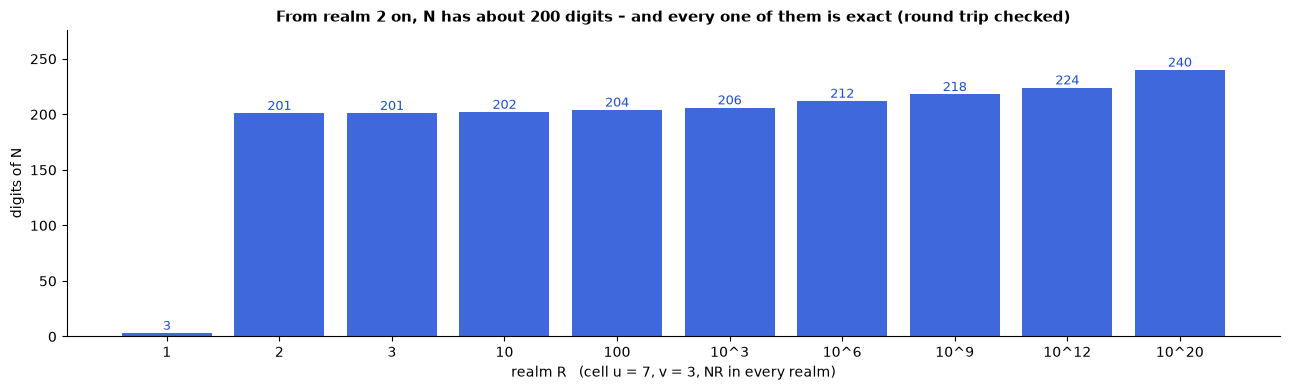

In [5]:
realms = [1, 2, 3, 10, 100, 10**3, 10**6, 10**9, 10**12, 10**20]
rows = []
for R in realms:
    n = nhydb.dynadron_n(R, 7, 3, "NR")
    a = nhydb.n_to_dynadron_address(n)
    assert (a["realm"], a["u"], a["v_local"], a["lane_name"]) == (R, 7, 3, "NR")
    rows.append({"R": R, "digits of N": digits(n)})
size = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(13, 4))
labels = [f"10^{digits(R) - 1}" if R >= 1000 else str(R) for R in realms]
ax.bar(range(len(realms)), size["digits of N"], color=COLORS["A"], alpha=0.85)
for i, d in enumerate(size["digits of N"]):
    ax.text(i, d + 3, str(d), ha="center", fontsize=9, color=COLORS["A"])
ax.set_xticks(range(len(realms)))
ax.set_xticklabels(labels)
ax.set_xlabel("realm R   (cell u = 7, v = 3, NR in every realm)")
ax.set_ylabel("digits of N")
ax.set_title("From realm 2 on, N has about 200 digits – and every one of them is exact (round trip checked)")
ax.set_ylim(0, size["digits of N"].max() * 1.15)
plt.tight_layout()
plt.show()

**What happened?** Realm 1 gives small numbers (here `N = 103`). From realm 2 on, `V` exceeds
`10^100`, so `G² ≈ V²` has about 200 digits. A realm number with 20 digits adds only about 40
more digits. Every number was converted back to its address without any loss – there is no
floating point anywhere in the address arithmetic.

> **Why we plot digits:** a 200-digit integer cannot be drawn on a normal axis without
> converting it to a floating-point number (and losing almost all digits). Counting digits is
> exact.

## 3 · Distant realms in one small file

**Question:** We now store values in realms that are astronomically far apart. What does it cost?

▶ **Run it:**

In [6]:
PATH = db_path("realms.nhydb")
REALMS = [1, 2, 1000, 10**6, 10**12, 10**30]          # ▶ Try it: any positive integers

rows = []
with nhydb.create(PATH) as db:
    db.commit()
    base = os.path.getsize(PATH)
    for R in REALMS:
        db.create_realm(R, f"realm {R}")
        db.put_cell(R, 7, 3, f"hello from realm {R}", type="utf8", commit=True)
        n = nhydb.dynadron_n(R, 7, 3, "NL")
        rows.append({"realm": R if R < 10**4 else f"10^{digits(R) - 1}", "digits of N": digits(n),
                     "file bytes": os.path.getsize(PATH)})

with nhydb.open(PATH) as db:                          # read every value back by its number
    for R in REALMS:
        n = nhydb.dynadron_n(R, 7, 3, "NL")
        assert db.get_n(n, mode="cell")["value"] == f"hello from realm {R}"
print("all values read back by their number N ✓")

far = pd.DataFrame(rows)
far["bytes added"] = far["file bytes"].diff().fillna(far["file bytes"][0] - base).astype(int)
far

all values read back by their number N ✓


,realm,digits of N,file bytes,bytes added
0,1,2,9176,400
1,2,201,9576,400
2,1000,206,9976,400
3,10^6,212,10384,408
4,10^12,224,10800,416
5,10^30,260,11240,440


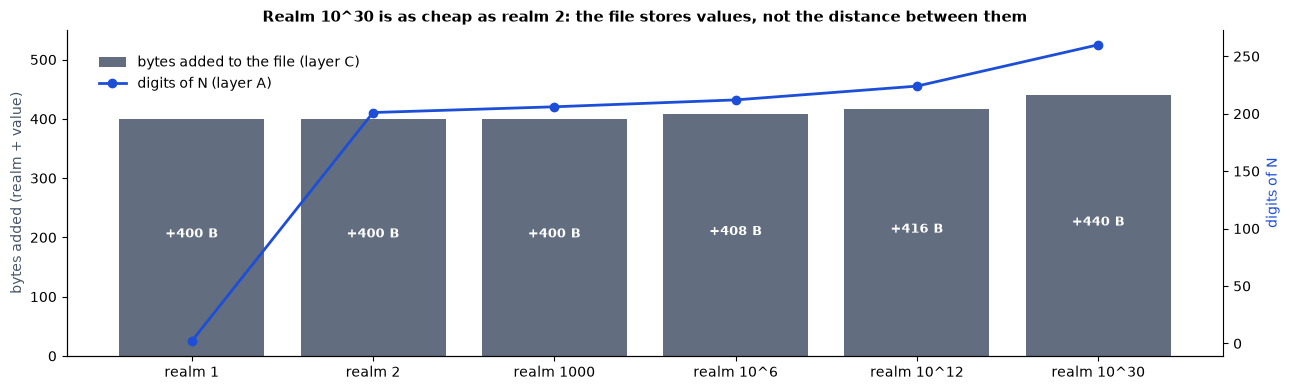

In [7]:
fig, ax1 = plt.subplots(figsize=(13, 4))
x = range(len(far))
ax1.bar(x, far["bytes added"], color=COLORS["C"], alpha=0.85, label="bytes added to the file (layer C)")
for xi, b in zip(x, far["bytes added"]):
    ax1.text(xi, b / 2, f"+{b} B", ha="center", fontsize=9, color="white", fontweight="bold")
ax1.set_ylabel("bytes added (realm + value)", color=COLORS["C"])
ax1.set_xticks(list(x))
ax1.set_xticklabels([f"realm {r}" for r in far["realm"]])
ax2 = ax1.twinx()
ax2.plot(list(x), far["digits of N"], "o-", color=COLORS["A"], lw=2, label="digits of N (layer A)")
ax2.set_ylabel("digits of N", color=COLORS["A"])
ax2.spines["right"].set_visible(True)
ax1.set_ylim(0, far["bytes added"].max() * 1.25)
ax1.set_title("Realm 10^30 is as cheap as realm 2: the file stores values, not the distance between them")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88), frameon=False)
plt.tight_layout()
plt.show()

**What happened?** Each new realm adds a few hundred bytes – mostly the new realm definition in
the commit (a schema change also updates the encrypted layout plan, notebook 12) plus one small
data block. Whether the realm is number 2 or number `10^30` makes practically no difference.
**Ah – the address space is unlimited, the file only holds what you wrote.**

## 4 · Logical and physical realms of MATH layouts

**Question:** A MATH formula (notebook 05) produces a global `V`. What if `V` crosses realm
boundaries – and what if those realms are already in use?

**Minimal explanation:** the formula only knows **logical** realms (`V` split by `T`). The engine
assigns each logical realm a **free physical realm** and keeps that assignment (the *realm map*)
in the layout plan. Physical realms of a MATH layout belong to it exclusively.

▶ **Run it:** realms 1 and 2 hold ordinary data; the formula `V = k·10^100 + x + 1` needs four
logical realms.

In [8]:
level_map = MathMap.compile("levels", ("k", "x"), u="x + 1", V="k * 10**100 + x + 1", side="NL")
inputs = [(k, x) for k in range(4) for x in range(3)]
print("logical realms needed:", dry_run(level_map, inputs).logical_realms)

MPATH = db_path("levels.nhydb")
with nhydb.create(MPATH) as db:
    for R in (1, 2):
        db.create_realm(R, f"ordinary {R}")
        db.put_cell(R, 1, 1, f"ordinary data in realm {R}", type="utf8")
    db.create_math_layout(MathMapLayoutSpec("levels", level_map, 64), layout_id=1, payload_type="varint")
    db.put_math_batch(1, [((k, x), 10 * k + x) for k, x in inputs], commit=True)
    extents = db.describe_math(1)["realm_extents"]
    cells = [db.get_math_cell(1, inp) for inp in inputs]

print("realm map:", extents)
table = pd.DataFrame([{"input (k, x)": c["_math_inputs"], "logical realm": c["_logical_realm"],
                       "physical realm": c["_realm"], "u": c["_u"], "local v": c["_v"],
                       "digits of N": digits(nhydb.dynadron_n(c["_realm"], c["_u"], c["_v"], c["_lane"]))}
                      for c in cells])
assert (table["physical realm"] == table["logical realm"] + 2).all()
table.head(6)

logical realms needed: (1, 2, 3, 4)
realm map: [{'logical_start': 1, 'logical_end': 4, 'physical_start': 3, 'physical_end': 6}]


,"input (k, x)",logical realm,physical realm,u,local v,digits of N
0,"(0, 0)",1,3,1,1,201
1,"(0, 1)",1,3,2,2,201
2,"(0, 2)",1,3,3,3,201
3,"(1, 0)",2,4,1,1,201
4,"(1, 1)",2,4,2,2,201
5,"(1, 2)",2,4,3,3,201


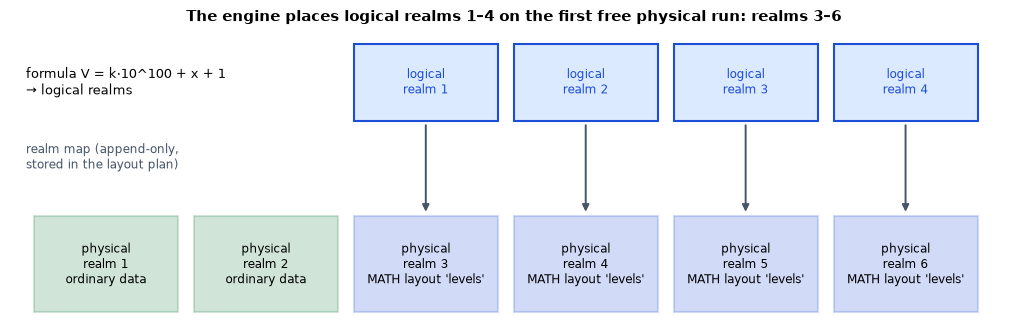

In [9]:
fig, ax = plt.subplots(figsize=(13, 3.8))
for R in range(1, 7):
    used_by = "ordinary data" if R <= 2 else "MATH layout 'levels'"
    color = COLORS["B"] if R <= 2 else COLORS["A"]
    ax.add_patch(Rectangle((R - 0.45, 0), 0.9, 1, facecolor=color, alpha=0.2, edgecolor=color, lw=1.5))
    ax.text(R, 0.5, f"physical\nrealm {R}\n{used_by}", ha="center", va="center", fontsize=8.5)
for L in range(1, 5):
    ax.add_patch(Rectangle((L + 1.55, 2), 0.9, 0.8, facecolor=COLORS["A_light"], edgecolor=COLORS["A"], lw=1.5))
    ax.text(L + 2, 2.4, f"logical\nrealm {L}", ha="center", va="center", fontsize=8.5, color=COLORS["A"])
    ax.annotate("", xy=(L + 2, 1.02), xytext=(L + 2, 1.98),
                arrowprops=dict(arrowstyle="-|>", color=COLORS["C"], lw=1.4))
ax.text(0.5, 2.4, "formula V = k·10^100 + x + 1\n→ logical realms", fontsize=9, va="center")
ax.text(0.5, 1.5, "realm map (append-only,\nstored in the layout plan)", fontsize=8.5, color=COLORS["C"])
ax.set_xlim(0.4, 6.7)
ax.set_ylim(-0.1, 2.95)
ax.axis("off")
ax.set_title("The engine places logical realms 1–4 on the first free physical run: realms 3–6")
plt.show()

**What happened?** The formula is unchanged – it still thinks in logical realms 1 to 4. The
engine found realms 1 and 2 occupied and placed the layout on physical realms 3 to 6. The stored
cell, and therefore its `N`, uses the **physical** realm. Readers never need to know: they ask
with the same inputs (`get_math`).

A safety budget limits how many realms a layout may claim (`realm_auto_limit`, 64 here):

In [10]:
greedy = MathMap.compile("greedy", ("k",), u="1", V="k * 10**100 + 1", side="NL")
with nhydb.open(MPATH) as db:
    db.create_math_layout(MathMapLayoutSpec("greedy", greedy, 3), layout_id=2, payload_type="varint")
    try:
        db.put_math_batch(2, [((k,), k) for k in range(5)])        # needs 5 realms, budget 3
    except nhydb.RealmBudgetExceeded as e:
        print("RealmBudgetExceeded:", e)
    assert db.get_math(2, (0,)) is None                              # nothing was written

RealmBudgetExceeded: MATH realm auto limit exceeded: existing=0, new=5, resulting=5, limit=3


## 5 · Huge address space, limited formula resources

**Question:** If addresses are unlimited, can a formula compute anything?

No – and these are two different things:

| | address space | formula evaluation |
|---|---|---|
| what is limited | nothing: `u`, `v`, realms are unbounded integers | size of intermediate results |
| default limit | – | `2^20` bits per intermediate result (about 315,000 digits) |
| why | addresses cost nothing until written | protects against formulas like `2 ** (10**9)` |

In [11]:
from nhydb.math import MathExpression, get_math_max_intermediate_bits

print("limit:", get_math_max_intermediate_bits(), "bits")
e = MathExpression.compile("10 ** x", ("x",))
print("10**300 has", digits(e.evaluate(x=300)), "digits – fine")
try:
    e.evaluate(x=400_000)                          # 400,000 digits > 2^20 bits
except nhydb.MathDomainError as err:
    print("10**400000 →", type(err).__name__, ":", err)

# A cell far beyond what any formula needs is still a perfectly valid address:
n = nhydb.dynadron_n(10**50, 10**40, 10**99, "NR")
print("N of (R=10^50, u=10^40, v=10^99, NR) has", digits(n), "digits; round trip:",
      nhydb.n_to_dynadron_address(n)["realm"] == 10**50)

limit: 1048576 bits
10**300 has 301 digits – fine
10**400000 → MathDomainError : intermediate result exceeds math_max_intermediate_bits=1048576 (estimated 1328772 bits)
N of (R=10^50, u=10^40, v=10^99, NR) has 300 digits; round trip: True


## ▶ Try it

Choose a realm and a cell; the cell computes `N`, splits it back, and shows where the cell sits
on the global axis.

In [12]:
# ▶ Try it: change these values and re-run
R, U, V_LOCAL, LANE = 42, 5, 17, "NR"

n = nhydb.dynadron_n(R, U, V_LOCAL, LANE)
a = nhydb.n_to_dynadron_address(n)
V_global = nhydb.global_v(R, V_LOCAL)
print(f"cell (R={R}, u={U}, v={V_LOCAL}, {LANE})")
print(f"global V = (R−1)·T + v = {R - 1}·10^100 + {V_LOCAL}")
print(f"G = u + V has {digits(U + V_global)} digits;  N has {digits(n)} digits")
print(f"N begins with {str(n)[:20]}… and ends with …{str(n)[-20:]}")
assert (a["realm"], a["u"], a["v_local"], a["lane_name"]) == (R, U, V_LOCAL, LANE)
print("round trip ✓")

cell (R=42, u=5, v=17, NR)
global V = (R−1)·T + v = 41·10^100 + 17
G = u + V has 102 digits;  N has 204 digits
N begins with 16810000000000000000… and ends with …00000000000000000501
round trip ✓


## Your turn

**Task:** a formula produced the global coordinate `V = 3·10^100 + 7`. Which logical realm and
which local `v` is that? Work it out, then check with `split_global_v`.

In [13]:
# Solution: V = (R − 1)·T + v  →  R − 1 = 3, v = 7  →  realm 4, local v = 7
answer = nhydb.split_global_v(3 * 10**100 + 7)
print(answer)
assert answer == (4, 7)

(4, 7)


## ⏩ Advanced: the boundary points in realm 2

The boundary points GZ and N0 exist in every realm, because the formulas are the same – only
`V` is shifted. The first NR cell of realm 2 for `u = 1` lies right after a perfect square:

In [14]:
n = nhydb.dynadron_n(2, 1, 1, "NR")                  # u = 1, V = T + 1, G = T + 2
G = 1 + (T + 1)
assert n == G * G + (T + 1)
for m in (G * G - 1, G * G, G * G + 1):
    try:
        k = nhydb.n_to_dynadron_address(m)["lane_name"]
    except nhydb.AddressError:
        k = "GZ" if math.isqrt(m) ** 2 == m else "N0"
    print(f"G² {m - G * G:+d}: {k}")

G² -1: NL
G² +0: GZ
G² +1: NR


## Summary

* Realms are consecutive stretches of `T = 10^100` positions on one global axis: `V = (R − 1)·T + v`.
* `N` is computed from `u` and `V` with exact integers; from realm 2 on it has about 200 digits – and inverts without loss.
* Distant realms cost no extra space: the file stores values, not distances.
* MATH layouts think in logical realms; the engine maps them to free physical realms (realm map, budget).
* The address space is unbounded; only formula evaluation has a resource limit.

## Where to go next

* [08 · Addresses Are Not Search Indexes](08_addresses_are_not_indexes_v1.ipynb) – finding data by content.
* [12 · One Layout Plan, Two Views](12_encrypted_layout_and_key_v1.ipynb) – where realms and realm maps are stored.

**Cookbook sections:** 9 (Addresses and the number N), 18 (MATH_MAP), 19 (Configuration and limits) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
